# Project 1 — Wholesale customer segmentation
**DSC8307: Data Mining, Modeling and Analytics | Advent 2026**

**Name:** Tayebwa Yonah  
**Access number:** B28697

## Aim of the project
This project groups wholesale customers by their spending on six product categories and considers how the distributor could serve each group. K-means, Ward hierarchical clustering and DBSCAN are compared using the same prepared data.

Channel and Region are kept for interpreting the groups. They are not clustering inputs because distances between their numeric codes would have little meaning. The comparison considers separation, group sizes, stability and how easily each solution translates into service decisions.

There are no known correct cluster labels. The results should therefore be read as useful customer profiles rather than a definitive classification. All calculations use the supplied data, with a matching public copy available through the download helper.

**Data access:** The first run downloads the public benchmark data using `download_data.py`. The helper verifies the assignment data checksum before analysis. Internet access is required on the first run; subsequent runs use cached files. Raw data and individual customer/transaction exports are excluded from Git; published outputs contain aggregate tables and figures.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib, json, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
thread_limit = threadpool_limits(limits=2)
SEED = 8307
rng = np.random.default_rng(SEED)
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'grid.alpha': .2})
from download_data import ensure_data
DATA = Path('data')
OUT = Path('results'); OUT.mkdir(exist_ok=True)
print({'python':platform.python_version(), 'numpy':np.__version__, 'pandas':pd.__version__, 'sklearn':sklearn.__version__})
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram
path = ensure_data('wholesale', DATA)
df = pd.read_csv(path)
features = ['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicatessen']
print('SHA256:', hashlib.sha256(path.read_bytes()).hexdigest())
display(df.describe().T)
display(pd.DataFrame({'dtype':df.dtypes.astype(str), 'missing':df.isna().sum(), 'unique':df.nunique()}))
print('Rows:',len(df),'Exact duplicate rows:',df.duplicated().sum())
assert len(df)==440 and df[features].ge(0).all().all()
assert df.isna().sum().sum()==0


Matplotlib is building the font cache; this may take a moment.


{'python': '3.12.13', 'numpy': '2.5.4', 'pandas': '3.1.1', 'sklearn': '1.9.1'}


SHA256: 8f79c9a3e0bc677502d545f986bc42a5cd4dc73ddb6c33044b1a2cc14ed0aaba


,count,mean,std,min,25%,50%,75%,max
Channel,440.0,1.322727,0.468052,1.0,1.00,1.0,2.00,2.0
Region,440.0,2.543182,0.774272,1.0,2.00,3.0,3.00,3.0
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0
Delicatessen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0


,dtype,missing,unique
Channel,int64,0,2
Region,int64,0,3
Fresh,int64,0,433
Milk,int64,0,421
Grocery,int64,0,430
Frozen,int64,0,426
Detergents_Paper,int64,0,417
Delicatessen,int64,0,403


Rows: 440 Exact duplicate rows: 0


## Understanding and preparing the data
Spending differs widely between customers, and some categories have long right tails. A very large purchase total is not enough reason to remove a customer: it could be a valid account that matters to the distributor.

All complete, valid records are retained. The `log1p` transformation reduces the influence of extreme spending and works when a value is zero. Standardization then gives each category a comparable role in Euclidean distance. This puts more emphasis on relative purchasing patterns and less on account size. Later checks show how the groups change with robust scaling and with untransformed spending.

The checks below report missing values, duplicates, zeros and skewness. Identical spending records would need investigation before being treated as duplicate customers.

,raw_skew,log_skew,zero_count
Fresh,2.561323,-1.575326,0
Milk,4.053755,-0.224063,0
Grocery,3.587429,-0.674938,0
Frozen,5.907986,-0.352655,0
Detergents_Paper,3.631851,-0.235961,0
Delicatessen,11.151586,-1.091827,0


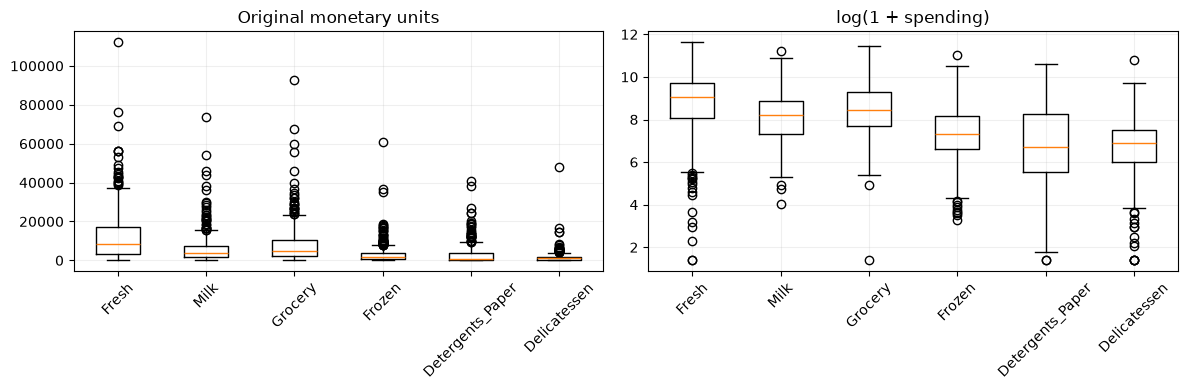

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
Fresh,1.00,0.10,-0.01,0.35,-0.10,0.24
Milk,0.10,1.00,0.73,0.12,0.66,0.41
Grocery,-0.01,0.73,1.00,-0.04,0.92,0.21
Frozen,0.35,0.12,-0.04,1.00,-0.13,0.39
Detergents_Paper,-0.10,0.66,0.92,-0.13,1.00,0.07
Delicatessen,0.24,0.41,0.21,0.39,0.07,1.00


In [2]:
display(pd.DataFrame({'raw_skew':df[features].skew(), 'log_skew':np.log1p(df[features]).skew(), 'zero_count':df[features].eq(0).sum()}))
fig, ax = plt.subplots(1,2,figsize=(12,4))
ax[0].boxplot(df[features],tick_labels=features); ax[0].set_title('Original monetary units')
ax[1].boxplot(np.log1p(df[features]),tick_labels=features); ax[1].set_title('log(1 + spending)')
for a in ax: a.tick_params(axis='x',rotation=45)
plt.tight_layout(); plt.show()
display(df[features].corr().round(2))
X = StandardScaler().fit_transform(np.log1p(df[features]))


## Is there evidence of cluster tendency?
Before looking for groups, the analysis checks whether customers are distributed like random points in the transformed spending space. Each of 50 repetitions compares 44 sampled customers with 44 points drawn uniformly inside the same bounding box.

Let **w** be the distance from a sampled customer to its nearest other customer, and **u** the distance from a random point to its nearest customer. The statistic is H = Σuᵈ / (Σuᵈ + Σwᵈ), with d = 6. A high value suggests that the observations are concentrated rather than uniformly spread.

A simulated uniform dataset provides a reference for comparison. This avoids relying only on a fixed cutoff such as 0.5. The result still depends on the bounding box, tails and correlations: it can support further clustering, but cannot establish how many distinct customer types exist.

,observed,uniform_null
count,50.000000,50.000000
mean,0.995346,0.468398
std,0.007455,0.072149
min,0.966566,0.314053
25%,0.995780,0.406439
50%,0.998612,0.465656
75%,0.999359,0.519207
max,0.999876,0.609753


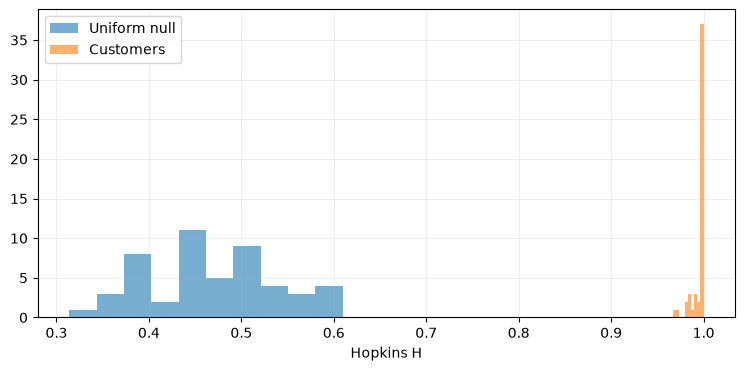

Median H: 0.999; uniform null 95th percentile: 0.588


In [3]:
def hopkins(A, seed):
    r = np.random.default_rng(seed); m = max(10,len(A)//10)
    nn = NearestNeighbors(n_neighbors=2).fit(A)
    w = nn.kneighbors(A[r.choice(len(A),m,replace=False)])[0][:,1]
    artificial = r.uniform(A.min(0), A.max(0), size=(m,A.shape[1]))
    u = nn.kneighbors(artificial,n_neighbors=1)[0][:,0]
    return (u**A.shape[1]).sum()/((u**A.shape[1]).sum()+(w**A.shape[1]).sum())
H = np.array([hopkins(X,SEED+i) for i in range(50)])
null = np.array([hopkins(np.random.default_rng(SEED+i).uniform(X.min(0),X.max(0),X.shape),SEED+i+100) for i in range(50)])
display(pd.DataFrame({'observed':H,'uniform_null':null}).describe())
plt.hist(null,alpha=.6,label='Uniform null'); plt.hist(H,alpha=.6,label='Customers'); plt.legend(); plt.xlabel('Hopkins H'); plt.show()
print(f'Median H: {np.median(H):.3f}; uniform null 95th percentile: {np.quantile(null,.95):.3f}')


## Comparing the clustering methods
K-means and Ward are fitted with two to eight groups. K-means provides compact groups and a simple way to assign new customers. Ward builds a hierarchy by joining groups with the smallest increase in within-group squared distance. DBSCAN instead identifies dense areas and marks sparse observations as noise.

For DBSCAN, the neighborhood radius comes from the 50th, 70th, 85th and 95th percentiles of neighbor distances. Two minimum-neighbor settings, 8 and 12, are tried. This ties the search to the observed distance scale.

The comparison uses silhouette and Calinski–Harabasz scores, where higher values are preferable, and Davies–Bouldin scores, where lower values are preferable. Group sizes and coverage also matter. DBSCAN scores are calculated only for assigned customers, so a high score after excluding many customers would need careful interpretation. A solution containing just one group has no defined silhouette score.

,clusters,coverage,min_size,silhouette,CH,DB,k,eps,min_samples
model,,,,,,,,,
KMeans k=2,2,1.000,188,0.290,189.050,1.352,2.0,NaN,NaN
Ward k=2,2,1.000,178,0.258,134.624,1.600,2.0,NaN,NaN
KMeans k=3,3,1.000,80,0.259,152.835,1.341,3.0,NaN,NaN
Ward k=3,3,1.000,53,0.255,116.799,1.539,3.0,NaN,NaN
KMeans k=4,4,1.000,61,0.189,131.353,1.542,4.0,NaN,NaN
Ward k=4,4,1.000,53,0.202,108.607,1.521,4.0,NaN,NaN
KMeans k=5,5,1.000,54,0.192,118.000,1.489,5.0,NaN,NaN
Ward k=5,5,1.000,18,0.203,100.015,1.386,5.0,NaN,NaN
KMeans k=6,6,1.000,20,0.194,108.400,1.429,6.0,NaN,NaN


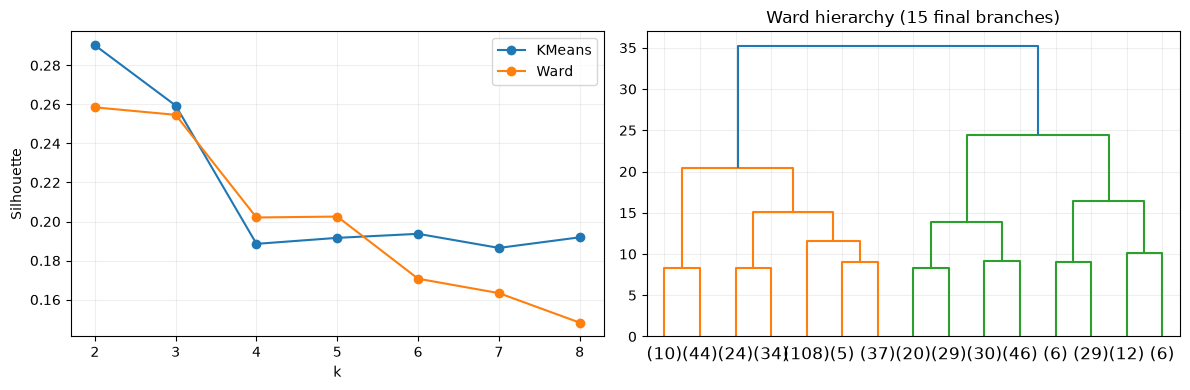

In [4]:
rows=[]; labels={}
def assess(name, lab, **params):
    mask=lab!=-1; A=X[mask]; L=lab[mask]; k=len(np.unique(L))
    ok=1<k<len(A)
    rows.append(dict(model=name,clusters=k,coverage=mask.mean(),min_size=int(pd.Series(L).value_counts().min()) if len(L) else 0,
        silhouette=silhouette_score(A,L) if ok else np.nan,
        CH=calinski_harabasz_score(A,L) if ok else np.nan,
        DB=davies_bouldin_score(A,L) if ok else np.nan,**params))
    labels[name]=lab
for k in range(2,9):
    assess(f'KMeans k={k}',KMeans(k,n_init=30,random_state=SEED).fit_predict(X),k=k)
    assess(f'Ward k={k}',AgglomerativeClustering(n_clusters=k,linkage='ward').fit_predict(X),k=k)
for m in [8,12]:
    dd=NearestNeighbors(n_neighbors=m).fit(X).kneighbors(X)[0][:,-1]
    for q in [.5,.7,.85,.95]:
        eps=float(np.quantile(dd,q))
        assess(f'DBSCAN m={m} q={q}',DBSCAN(eps=eps,min_samples=m).fit_predict(X),eps=eps,min_samples=m)
comparison=pd.DataFrame(rows).set_index('model')
display(comparison.round(3)); comparison.to_csv(OUT/'wholesale_comparison.csv')
fig,ax=plt.subplots(1,2,figsize=(12,4))
for family in ['KMeans','Ward']:
    sub=comparison.loc[comparison.index.str.startswith(family)]
    ax[0].plot(sub.k,sub.silhouette,'o-',label=family)
ax[0].legend(); ax[0].set(xlabel='k',ylabel='Silhouette')
dendrogram(linkage(X,method='ward'),truncate_mode='lastp',p=15,ax=ax[1]); ax[1].set_title('Ward hierarchy (15 final branches)')
plt.tight_layout(); plt.show()


## Choosing a solution and checking stability
The K-means solution with the highest silhouette score is used as the reference segmentation. It assigns every customer and can be applied to a new account using its nearest centroid. This selection rule is set before interpreting the spending profiles. The best Ward and DBSCAN results are also reported, including DBSCAN's coverage.

Two checks examine whether small changes produce a different answer. The first repeats K-means with 20 random initializations. The second fits 20 samples containing 80% of the customers, refitting the scaler within each sample, and then assigns all customers using the fitted model. Adjusted Rand index (ARI) measures agreement with the reference; 1 means identical grouping.

Finally, log-robust and raw-standardized spending show how much the answer depends on preparation. These checks assess the reliability of the segmentation, not its effect on sales or customer satisfaction.

Selected: KMeans k=2


,clusters,coverage,min_size,silhouette,CH,DB,k,eps,min_samples
model,,,,,,,,,
KMeans k=2,2,1.0,188,0.29,189.05,1.352,2.0,NaN,NaN


,clusters,coverage,min_size,silhouette,CH,DB,k,eps,min_samples
model,,,,,,,,,
Ward k=2,2,1.0,178,0.258,134.624,1.6,2.0,NaN,NaN


,clusters,coverage,min_size,silhouette,CH,DB,k,eps,min_samples
model,,,,,,,,,
DBSCAN m=8 q=0.5,2,0.727,8,0.229,19.179,0.847,NaN,1.05,8.0


,seed_ARI,subsample_ARI
count,20.000000,20.000000
mean,0.997726,0.945262
std,0.004040,0.060639
min,0.990906,0.801390
25%,0.997726,0.946050
50%,1.000000,0.968357
75%,1.000000,0.981853
max,1.000000,1.000000


log robust ARI to reference: 0.928 own-space silhouette: 0.253
raw standardized ARI to reference: 0.081 own-space silhouette: 0.614


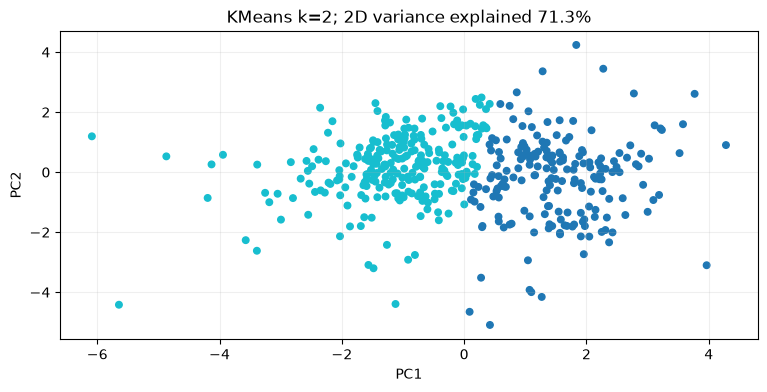

In [5]:
km_rows=comparison.loc[comparison.index.str.startswith('KMeans')]
selected=km_rows.silhouette.idxmax(); k=int(comparison.loc[selected,'k']); lab=labels[selected]
print('Selected:',selected)
for family in ['KMeans','Ward','DBSCAN']:
    eligible=comparison.loc[comparison.index.str.startswith(family)].dropna(subset=['silhouette'])
    if len(eligible): display(eligible.sort_values('silhouette',ascending=False).head(1).round(3))
stability=[]
for i in range(20):
    alt=KMeans(k,n_init=1,random_state=SEED+i).fit_predict(X)
    ix=np.random.default_rng(SEED+i).choice(len(X),int(.8*len(X)),replace=False)
    sc=StandardScaler().fit(np.log1p(df[features].iloc[ix]))
    submodel=KMeans(k,n_init=20,random_state=SEED+i).fit(sc.transform(np.log1p(df[features].iloc[ix])))
    pred=submodel.predict(sc.transform(np.log1p(df[features])))
    stability.append({'seed_ARI':adjusted_rand_score(lab,alt),'subsample_ARI':adjusted_rand_score(lab,pred)})
display(pd.DataFrame(stability).describe())
for name,A in [('log robust',RobustScaler().fit_transform(np.log1p(df[features]))),('raw standardized',StandardScaler().fit_transform(df[features]))]:
    alt=KMeans(k,n_init=30,random_state=SEED).fit_predict(A)
    print(name,'ARI to reference:',round(adjusted_rand_score(lab,alt),3),'own-space silhouette:',round(silhouette_score(A,alt),3))
pca=PCA(2).fit(X); P=pca.transform(X)
plt.scatter(P[:,0],P[:,1],c=lab,cmap='tab10',s=22); plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title(f'{selected}; 2D variance explained {pca.explained_variance_ratio_.sum():.1%}'); plt.show()


## What do the customer groups buy?
The profiles return to the original monetary units so that the differences are easier to interpret. Medians describe typical spending, while means show the effect of large accounts. Dividing a group's median by the overall median highlights its strongest categories.

Each group is named from its two strongest relative categories and its typical total spending. Channel and Region tables add context without being treated as correct cluster labels. Spending share refers to recorded purchases; it should not be confused with profit.

,segment,customers,customer_share,median_total,spend_share
cluster,,,,,
0,Higher-spend Detergents_Paper / Grocery customers,188,0.427,35222.5,0.577
1,Lower-spend Frozen / Fresh customers,252,0.573,19745.0,0.423


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
cluster,,,,,,
0,5406.0,7690.0,11527.0,1062.0,4495.0,1388.0
1,10348.0,1871.0,2406.0,2225.0,328.0,750.0


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
cluster,,,,,,
0,9356.0,10346.0,14697.0,2222.0,6085.0,2177.0
1,13973.0,2402.0,2919.0,3706.0,492.0,1038.0


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
cluster,,,,,,
0,0.64,2.12,2.42,0.70,5.51,1.44
1,1.22,0.52,0.51,1.46,0.40,0.78


Channel,1,2
cluster,,
0,0.287,0.713
1,0.968,0.032


Region,1,2,3
cluster,,,
0,0.154,0.101,0.745
1,0.190,0.111,0.698


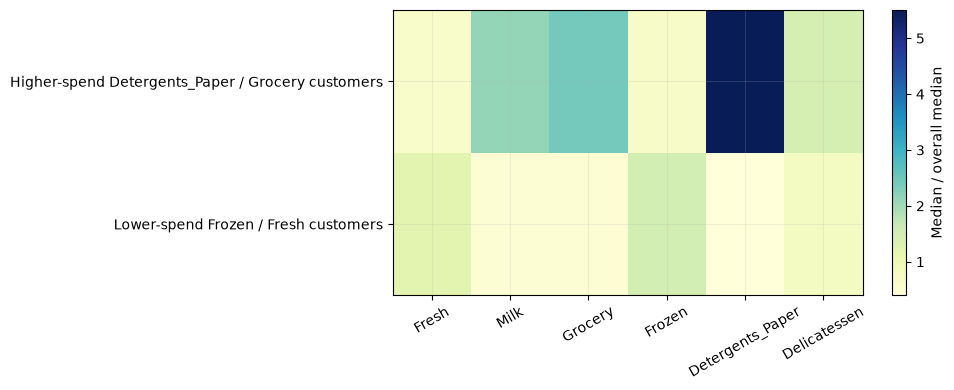

**Segment 0: Higher-spend Detergents_Paper / Grocery customers** — 188 customers; typical total spending 35,222 m.u. Prioritize availability of Detergents_Paper and Grocery. Offer consolidated replenishment, dependable delivery slots and volume pricing with margin checks.

**Segment 1: Lower-spend Frozen / Fresh customers** — 252 customers; typical total spending 19,745 m.u. Prioritize availability of Frozen and Fresh. Offer smaller packs, flexible minimum orders and opt-in replenishment reminders; test cross-selling before discounting.

The selected partition has silhouette **0.290**. This measures separation in the chosen transformed space and should be read alongside the other family results and stability distribution above. Cluster tendency median H is **0.999**, versus null median **0.466**. Nonuniform spending structure supports exploration, but does not prove discrete natural customer types.

In [6]:
profile=df.assign(cluster=lab)
med=profile.groupby('cluster')[features].median(); means=profile.groupby('cluster')[features].mean()
relative=med/df[features].median()
summary=profile.groupby('cluster').size().to_frame('customers')
summary['customer_share']=summary.customers/len(df)
summary['median_total']=profile.assign(total=df[features].sum(axis=1)).groupby('cluster').total.median()
summary['spend_share']=profile.groupby('cluster')[features].sum().sum(axis=1)/df[features].sum().sum()
names={}
for c in med.index:
    top=relative.loc[c].nlargest(2).index.tolist()
    size='Higher-spend' if summary.loc[c,'median_total']>df[features].sum(axis=1).median() else 'Lower-spend'
    names[c]=f'{size} {top[0]} / {top[1]} customers'
summary.insert(0,'segment',pd.Series(names))
display(summary.round(3)); display(med.round(0)); display(means.round(0)); display(relative.round(2))
for col in ['Channel','Region']:
    display(pd.crosstab(profile.cluster,profile[col],normalize='index').round(3))
fig,ax=plt.subplots(figsize=(10,4)); im=ax.imshow(relative,aspect='auto',cmap='YlGnBu'); ax.set_xticks(range(6),features,rotation=30); ax.set_yticks(range(k),[names[c] for c in med.index]); fig.colorbar(im,label='Median / overall median'); plt.tight_layout(); plt.show()
for c in med.index:
    top=relative.loc[c].nlargest(2).index.tolist()
    action=('Offer consolidated replenishment, dependable delivery slots and volume pricing with margin checks.' if summary.loc[c,'median_total']>df[features].sum(axis=1).median() else 'Offer smaller packs, flexible minimum orders and opt-in replenishment reminders; test cross-selling before discounting.')
    display(Markdown(f'**Segment {c}: {names[c]}** — {summary.loc[c,"customers"]} customers; typical total spending {summary.loc[c,"median_total"]:,.0f} m.u. Prioritize availability of {top[0]} and {top[1]}. {action}'))
profile.assign(segment=pd.Series(lab).map(names)).to_csv(OUT/'wholesale_customer_segments.csv',index=False)
summary.to_csv(OUT/'wholesale_segment_summary.csv')
display(Markdown(f"""The selected partition has silhouette **{comparison.loc[selected,'silhouette']:.3f}**. This measures separation in the chosen transformed space and should be read alongside the other family results and stability distribution above. Cluster tendency median H is **{np.median(H):.3f}**, versus null median **{np.median(null):.3f}**. Nonuniform spending structure supports exploration, but does not prove discrete natural customer types."""))


## Main findings and recommendations
The two-group K-means solution has a silhouette score of **0.290**, compared with **0.258** for the best Ward solution. Separation is modest, so some customers sit between the two profiles.

DBSCAN is less useful for a complete service segmentation. Its best-scoring setting assigns **72.7%** of customers to groups of 312 and 8, leaving 120 customers as noise. Its silhouette score is **0.229**. The other seven settings produce only one assigned group. Although its Davies–Bouldin score is lower, the unassigned customers and very uneven group sizes limit its usefulness here.

The K-means result is fairly stable across initializations (median ARI **1.000**) and subsamples (median **0.968**), though the weakest subsample gives ARI **0.801**. Log-robust scaling also agrees closely, with ARI **0.928**. Raw-standardized spending gives a different answer: its silhouette is **0.614**, but agreement with the chosen groups is only **0.081**. That result places more emphasis on spending size. The scores come from different representations and do not establish that one view is automatically better.

**Grocery and detergents customers:** This group contains **188 customers** and accounts for **57.7%** of recorded spending. Median grocery spending is **11,527 m.u.**, compared with **2,406 m.u.** in the other group. Reliable replenishment of groceries and cleaning products, consolidated deliveries and carefully tested volume offers would suit this profile.

**Fresh and frozen customers:** This group contains **252 customers**. Median fresh spending is **10,348 m.u.**, compared with **5,406 m.u.** in the first group. Fresh and frozen availability, dependable cold-chain delivery and flexible mixed orders are sensible service priorities.

Channel 2 represents **71.3%** of the first group but only **3.2%** of the second. Region distributions are more similar. This supports a useful interpretation of the profiles, but does not prove that the grouping is correct.

The alternative methods' profiles below show what their groups look like in monetary units. DBSCAN's noise customers are reported separately; group numbers do not imply matching segments across methods.

In [7]:
for family in ['Ward','DBSCAN']:
    candidate=comparison.loc[comparison.index.str.startswith(family)].dropna(subset=['silhouette']).silhouette.idxmax()
    alt_labels=labels[candidate]
    alt=df.assign(cluster=alt_labels)
    alt_med=alt.groupby('cluster')[features].median()
    alt_summary=alt.groupby('cluster').size().to_frame('customers')
    alt_summary['name']=['Sparse / unassigned customers' if c==-1 else ' / '.join((alt_med.loc[c]/df[features].median()).nlargest(2).index)+' oriented' for c in alt_med.index]
    display(Markdown(f'**{candidate}**'))
    display(alt_summary); display(alt_med.round(0))
    print('ARI with reference, including noise as a separate label:',round(adjusted_rand_score(lab,alt_labels),3))
    alt_summary.join(alt_med).to_csv(OUT/f'wholesale_{family.lower()}_profiles.csv')


**Ward k=2**

,customers,name
cluster,,
0,178,Detergents_Paper / Grocery oriented
1,262,Frozen / Fresh oriented


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
cluster,,,,,,
0,4500.0,7339.0,11099.0,957.0,4584.0,1189.0
1,11113.0,2028.0,2584.0,2382.0,358.0,864.0


ARI with reference, including noise as a separate label: 0.639


**DBSCAN m=8 q=0.5**

,customers,name
cluster,,
-1,120,Sparse / unassigned customers
0,312,Frozen / Fresh oriented
1,8,Detergents_Paper / Grocery oriented


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
cluster,,,,,,
-1,5406.0,4745.0,6183.0,982.0,714.0,549.0
0,9390.0,3238.0,4064.0,1740.0,811.0,1012.0
1,1264.0,8655.0,11998.0,134.0,5244.0,1481.0


ARI with reference, including noise as a separate label: 0.034


## Limits and practical use
K-means is the most straightforward option for assigning new accounts. Ward helps show relationships at different levels, while DBSCAN can flag sparse customers for separate review. The two-dimensional plot is only a projection and can hide overlap in the full six-feature space.

Annual spending mixes business size with product preference. There are no order dates, margins or service outcomes, so the analysis cannot show whether these profiles persist or improve profitability. Correlated categories and the choice of transformation also affect the groups.

The recommendations should be tested with small service pilots. Retention, delivery performance and gross margin would be useful outcomes to measure. A cluster label should help plan an offer, not become a reason to give a customer poorer service.

## References and attribution
- Supplied `wholesale-customers.csv` and `wholesale-customers-README.txt` (assignment materials); category descriptions follow that README. The Region README contains a spelling error; integer Region values are retained without inferring geography.
- [scikit-learn clustering guide](https://scikit-learn.org/stable/modules/clustering.html): K-means, Ward, clustering evaluation and their assumptions.
- [DBSCAN documentation](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html): density parameters and noise label −1.
- Hopkins, B. and Skellam, J. G. (1954), “A new method for determining the type of distribution of plant individuals,” *Annals of Botany*, 18(2), 213–227. The implemented distance experiment is a Monte Carlo adaptation; its uniform reference is explicit above.

**Preparation disclosure:** This analysis and code were prepared with AI assistance. The submitting student should verify all outputs, understand the methods and comply with institutional disclosure requirements.

Public data attribution: Cardoso, M. (2013). [Wholesale customers](https://archive.ics.uci.edu/dataset/292/wholesale+customers), UCI Machine Learning Repository, DOI 10.24432/C5030X. CC BY 4.0. The public header Delicassen is normalized to Delicatessen; numerical records and row order are verified against the supplied CSV.
